# FastSpeech 2 text-to-speech - Telugu (IndicTTS)

This notebook trains a multi-speaker FastSpeech 2 text-to-speech model for Telugu, using the PyTorch implementation
[ming024/FastSpeech2](https://github.com/ming024/FastSpeech2) with the modifications described in the project README.
It covers the full pipeline: data selection, pronunciation lexicon, forced alignment, feature extraction, training,
inference on the five test sentences, and the variance-adaptor plots (duration, pitch, energy).

**Data:** [IndicTTS Telugu](https://huggingface.co/datasets/SPRINGLab/IndicTTS_Telugu) (`SPRINGLab/IndicTTS_Telugu`), studio-recorded monolingual Telugu from one male and one female speaker (IndicTTS database, IIT Madras).

**Runtime.** Data preparation (sections 2-11) runs on CPU; training (sections 13-15) needs a GPU. The notebook can be run
with *Runtime -> Run all*: stages that are already complete are skipped, and a stage that fails stops the run.
If the runtime has no GPU, execution stops before training with a message; switching the runtime type to a T4 GPU and
running all cells again continues from there. Prepared data and checkpoints are kept on Google Drive, so a disconnected
session can resume.

**Version 2 (this notebook).** The first run (version 1, 30,000 steps) overfitted: the validation loss reached its minimum very early while the audio kept improving, and the pitch and energy losses on the training set were far below those on the validation set. This version changes the training recipe only; data, alignment and features are the same as in version 1:
- a shorter schedule (15,000 steps) with the learning rate reduced earlier (steps 8000, 11000, 13000);
- AdamW optimiser with decoupled weight decay 0.01 (version 1 used Adam without weight decay); an earlier attempt with ordinary L2 weight decay 0.01 and dropout 0.3 stopped the model from learning (training loss rose after step 1500) and was abandoned;
- a snapshot of the weights every 1000 steps instead of only "best" and "last";
- the final checkpoint is chosen by objective measurements on the validation set (section 14b) instead of the validation loss.

## 1. Environment
Checks for a GPU and defines two small helpers: `sh()` runs a shell command and raises on failure, `have()` tests whether files exist.

In [2]:
!nvidia-smi -L || echo 'No GPU in this session'

import os, glob, subprocess, shutil, zipfile

def sh(cmd):
    # run a shell command, stream its output, and raise if it fails
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, executable='/bin/bash')
    out = []
    for line in p.stdout:
        print(line, end=''); out.append(line)
    if p.wait() != 0:
        raise RuntimeError('Command failed (exit code %d) - see the output above.' % p.returncode)
    return ''.join(out)

def have(pattern):
    return len(glob.glob(pattern)) > 0

os.environ['FS2_WORK'] = '/content/work'
print('helpers ready')

/bin/bash: line 1: nvidia-smi: command not found
No GPU in this session
helpers ready


## 2. Project code
Mounts Google Drive and unpacks `project.zip` (the code, configuration files and pretrained HiFi-GAN vocoder). Prepared data and checkpoints are stored in `fs2_telugu/` on Drive.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
shutil.rmtree('/content/project', ignore_errors=True)
zipfile.ZipFile('/content/drive/MyDrive/project.zip').extractall('/content')
os.chdir('/content/project')
os.makedirs('/content/drive/MyDrive/fs2_telugu', exist_ok=True)
PREP_TAR = '/content/drive/MyDrive/fs2_telugu/prepared_data.tar'
print('code ready:', os.listdir('/content/project'))

Mounted at /content/drive
code ready: ['Telugu', 'README.md', '.gitignore', 'common', 'Results', 'fastspeech2', 'notebooks', 'English', 'requirements.txt', 'Report', 'tests']


## 3. Python dependencies
Installs the audio, alignment-file and text-processing packages; PyTorch is already part of the Colab image. NLTK data is needed by the grapheme-to-phoneme tool.

In [4]:
sh('pip install -q pyworld tgt g2p-en inflect soundfile librosa pyyaml scikit-learn matplotlib datasets unidecode')
import nltk
for p in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'cmudict']:
    nltk.download(p, quiet=True)
print('ok')

ok


## 4. Montreal Forced Aligner
FastSpeech 2 needs the duration of every phone, which comes from forced alignment of each recording against its transcript.
The Montreal Forced Aligner (MFA) is installed with micromamba in its own environment so it does not interfere with the
Python packages above. The step is skipped when prepared data already exists on Drive.

In [4]:
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - aligner not needed')
else:
    sh('''
    set -e
    export MAMBA_ROOT_PREFIX=$HOME/micromamba
    if [ ! -f $MAMBA_ROOT_PREFIX/bin/micromamba ]; then
      mkdir -p $MAMBA_ROOT_PREFIX/bin
      curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C $MAMBA_ROOT_PREFIX bin/micromamba
    fi
    if [ ! -d $MAMBA_ROOT_PREFIX/envs/mfa ]; then
      $MAMBA_ROOT_PREFIX/bin/micromamba create -y -n mfa -c conda-forge python=3.11 montreal-forced-aligner
    fi
    $MAMBA_ROOT_PREFIX/bin/micromamba run -n mfa mfa version
    ''')

prepared data found on Drive - aligner not needed


## 5. Hugging Face access
1. Create a Hugging Face account (or log in).
2. Open https://huggingface.co/datasets/SPRINGLab/IndicTTS_Telugu and accept the conditions if the page asks for it.
3. Create a read token at https://huggingface.co/settings/tokens (*Create new token* -> type **Read**) and paste it in the prompt below.

The token is read through a hidden prompt and is not stored in the notebook.

In [5]:
from getpass import getpass
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - token not needed')
elif not os.environ.get('HF_TOKEN'):
    os.environ['HF_TOKEN'] = getpass('Hugging Face token: ')
    print('token received, length', len(os.environ['HF_TOKEN']))

prepared data found on Drive - token not needed


## 6. Restore previously prepared data
If a previous session already finished sections 7-10, the prepared data is restored from Drive and those stages are skipped.

In [5]:
tar = PREP_TAR
if not have('/content/work/preprocessed_data/*/train.txt') and os.path.exists(tar):
    os.makedirs('/content/work', exist_ok=True)
    sh('tar -xf ' + tar + ' -C /content')
    print('restored prepared data from Drive')
else:
    print('nothing to restore')

restored prepared data from Drive


## 7. Data selection
Each speaker contributes the same fraction of its audio. Telugu text is converted to phones with a rule-based grapheme-to-phoneme module (`common/telugu_frontend.py`), which also expands numbers, times and ordinals into Telugu words.
Clips shorter than 1 s or longer than the limit set in `config.yaml` are dropped, and the selected clips are split by
utterance into training (~5 h) and validation (~1 h) sets, so no clip appears in both. Audio is resampled to 22.05 kHz mono and
the transcripts are normalised. The per-speaker statistics are written to `selection_stats.json`.

In [7]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
elif have('/content/work/raw_data/*/split.json'):
    print('data already downloaded - skipping')
else:
    sh('python Telugu/preprocess.py --stage select')

data already prepared - skipping


In [8]:
sh('cat /content/work/raw_data/*/selection_stats.json | head -40')

{
  "train_hours": 4.998059780092593,
  "val_hours": 1.0031423900462961,
  "train_utterances": 2245,
  "val_utterances": 459,
  "n_speakers": 2,
  "dropped": {
    "too long": 3221,
    "too short": 12
  },
  "pseudo_speaker_columns": [],
  "pseudo_speaker_keys": {},
  "settings": {
    "train_hours": 5.0,
    "val_hours": 1.0,
    "seed": 1234,
    "min_seconds": 1.0,
    "max_seconds": 15.0,
    "min_speaker_seconds": 60
  },
  "per_speaker": {
    "0": {
      "train_s": 5710.1,
      "val_s": 1149.0,
      "train_n": 639,
      "val_n": 131
    },
    "1": {
      "train_s": 12282.9,
      "val_s": 2462.3,
      "train_n": 1606,
      "val_n": 328
    }
  }
}

'{\n  "train_hours": 4.998059780092593,\n  "val_hours": 1.0031423900462961,\n  "train_utterances": 2245,\n  "val_utterances": 459,\n  "n_speakers": 2,\n  "dropped": {\n    "too long": 3221,\n    "too short": 12\n  },\n  "pseudo_speaker_columns": [],\n  "pseudo_speaker_keys": {},\n  "settings": {\n    "train_hours": 5.0,\n    "val_hours": 1.0,\n    "seed": 1234,\n    "min_seconds": 1.0,\n    "max_seconds": 15.0,\n    "min_speaker_seconds": 60\n  },\n  "per_speaker": {\n    "0": {\n      "train_s": 5710.1,\n      "val_s": 1149.0,\n      "train_n": 639,\n      "val_n": 131\n    },\n    "1": {\n      "train_s": 12282.9,\n      "val_s": 2462.3,\n      "train_n": 1606,\n      "val_n": 328\n    }\n  }\n}'

## 8. Pronunciation lexicon and forced alignment
The lexicon maps every word of the selected transcripts to phones. The aligner is then trained on the selected data and writes
one phone-level TextGrid per utterance. Recipe: MFA's full training pipeline (monophone, triphone, LDA-MLLT and speaker-adaptive stages), the same recipe for both languages so the results are comparable; this is the slowest preparation step (a few hours on CPU). Utterances the aligner cannot align are reported and excluded.

In [9]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
else:
    sh('python Telugu/preprocess.py --stage lexicon')
    if have('/content/work/preprocessed_data/*/TextGrid/*/*.TextGrid'):
        print('alignment already done - skipping')
    else:
        sh('python Telugu/preprocess.py --stage align --num_jobs 4')

data already prepared - skipping


## 9. Feature extraction
Computes mel-spectrograms, phoneme-level pitch (F0) and energy, and durations from the alignments. Pitch and energy statistics for normalisation are fitted on the training files only.

In [10]:
if not have('/content/work/preprocessed_data/*/train.txt'):
    sh('python Telugu/preprocess.py --stage features')
sh('cat /content/work/preprocessed_data/*/preprocess_summary.json')

{
  "train": {
    "utterances": 2228,
    "hours": 3.567,
    "speakers": 2
  },
  "val": {
    "utterances": 455,
    "hours": 0.718,
    "speakers": 2
  }
}

'{\n  "train": {\n    "utterances": 2228,\n    "hours": 3.567,\n    "speakers": 2\n  },\n  "val": {\n    "utterances": 455,\n    "hours": 0.718,\n    "speakers": 2\n  }\n}'

## 10. Back up the prepared data
Archives the prepared data to Drive so that a later session can skip sections 7-9.

In [11]:
import tarfile
files = ['work/preprocessed_data', 'work/lexicon.txt']
for pat in ('split.json', 'selection_stats.json'):
    files += [os.path.relpath(p, '/content') for p in glob.glob('/content/work/raw_data/*/' + pat)]
tmp = '/content/drive/MyDrive/fs2_telugu/prepared_data.tar.part'
with tarfile.open(tmp, 'w') as t:
    for f in files:
        t.add('/content/' + f, arcname=f)
os.replace(tmp, '/content/drive/MyDrive/fs2_telugu/prepared_data.tar')
sh('ls -lh /content/drive/MyDrive/fs2_telugu/')

total 465M
-rw------- 1 root root 465M Nov  5 13:49 prepared_data.tar


'total 465M\n-rw------- 1 root root 465M Nov  5 13:49 prepared_data.tar\n'

## 11. Sanity check
Plays a few of the selected recordings with their transcripts.

In [12]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/work/raw_data/*/*/*.wav'))[::700][:4]:
    print(w); print(open(w[:-4] + '.lab', encoding='utf-8').read()); ipd.display(ipd.Audio(w))

In [14]:
import os, sys, torch, IPython.display as ipd
os.chdir('/content/project'); sys.path.insert(0, '/content/project')
from common.configio import load_config, setup_paths
setup_paths()
from torch.utils.data import DataLoader
cfg, configs = load_config('/content/project/Telugu/config.yaml')
pre, mod, tr = configs
from dataset import Dataset
from utils.model import get_vocoder, vocoder_infer
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']
hop = pre['preprocessing']['stft']['hop_length']
for split in ('train', 'val'):
    ds = Dataset(split + '.txt', pre, tr, sort=False, drop_last=False)
    loader = DataLoader(ds, batch_size=8, shuffle=True, collate_fn=ds.collate_fn)
    ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, *_ = next(iter(loader))[0]
    print('=====', split, 'set: real recordings the model learns from' if split == 'train' else 'set: held-out recordings (never trained on)')
    for i in range(3):
        T = int(mel_lens[i])
        w = vocoder_infer(torch.from_numpy(mels[i, :T]).float().unsqueeze(0).transpose(1, 2).to(dev), voc, mod, pre, lengths=[T * hop])[0]
        print(raw[i]); ipd.display(ipd.Audio(w, rate=sr))

Removing weight norm...
===== train set: real recordings the model learns from
విశాఖ విస్తరణ జనాభా పెరిగిన దృష్ట్యా, పాత నగరాల్లో మరో ఎమ్.ఆర్.ఓ. కార్యాలయం ఏర్పాటు చెయ్యాల్సిన అవసరం ఉందని అన్నారు.


తరువాత ప్రజలందరూ చూస్తుండగా ఒర నుండి సర్రున కత్తి పైకి దూశాడు.


స్వర్గంలో ఇంద్రుడుగా ఉంటున్న బోధిసత్వుడు దేవగణాలను వెంటబెట్టుకుని నరకాలన్నిటినీ తనిఖి చేస్తూ కొంతకాలానికి మిత్రవిందకుడుండే చోటికి వచ్చాడు.


===== val set: held-out recordings (never trained on)
మరి కాసేపటికి శంతనుడు వచ్చి కరభుడితో ఇంక జాగుచేస్తే, మన ఇద్దరి మర్యాద దక్కదు, నువ్వు వెంటనే రాజును పట్టిన శరభుణ్ణి వదలగొట్టు, నీకు పెళ్ళి అయ్యేటట్టు నేను చూస్తాను అన్నాడు.


ఈ సందర్భంగా పలువురు మహిళలు, ఖాళీ బిందెలను ప్రదర్శిస్తూ, అధికారులు గ్రామ సర్పంచి వైఖరికి నిరసనగా, నినాదాలు చేసారు.


ఇంకనూ మీకు ఏమైనా సందేహాలుంటే చర్చా పేజీలో వ్రాయండి.


## 12. GPU check
Training requires a GPU. If the session has none, execution stops here; the prepared data is already saved.

In [15]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Data preparation is complete and saved to Drive. No GPU in this session, so stopping before training. '
                       'Switch the runtime type to a T4 GPU (Runtime > Change runtime type) and run all cells again; completed stages are skipped.')
print('GPU available:', torch.cuda.get_device_name(0))

GPU available: Tesla T4


## 13. Smoke test
Runs 30 training steps and one validation pass to confirm that the data, model and loss are wired up correctly. Skipped when a training run already exists.

In [16]:
if os.path.exists('/content/drive/MyDrive/fs2_telugu/ckpt/resume.pth.tar'):
    print('training already started earlier - skipping the smoke test')
else:
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)
    sh('python Telugu/train.py --total_step 30 --plots_dir /tmp/testplots')
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)

parameters: 35.1 M, device: cuda
starting from scratch
VALIDATION step 30  total 11.958 (mel 4.665 postnet 4.075 pitch 1.064 energy 1.202 dur 0.952)
  new best validation loss -> best_model_fp16.pth
saved checkpoint at step 30 (final)
finished at step 30
no /content/work/log/train_loss.csv
wrote /tmp/testplots/validation_loss.png


## 14. Training
15,000 steps (shortened schedule, learning rate annealed earlier, AdamW weight decay 0.01, dropout 0.2), batch size 16 (see `config.yaml`). Losses are logged to CSV every 50 steps and the validation loss is computed on the full
validation set every 500 steps. Checkpoints go to Drive and the run resumes automatically; the cell stops after 170 minutes
to stay within the Colab session limit and can simply be run again to continue. A snapshot of the weights is also kept every 1000 steps in `ckpt/snapshots/`; the final checkpoint is chosen in the next section from objective measurements, because the validation loss turned out to be a poor guide (see the report).

### Optimiser correction applied at run time
The project archive on Drive for this run still contained the first v2 settings (plain Adam with weight decay 0.01 and dropout 0.3), which stopped training from converging. The next cell switches the unpacked code to AdamW and dropout 0.2 and clears the checkpoints of the abandoned attempt, then training is started again from scratch. The archive that comes with the repository already contains these settings, so this cell is not needed when reproducing the results from the repository.

In [18]:
import re, shutil
p = '/content/project/fastspeech2/model/optimizer.py'
s = open(p).read().replace('torch.optim.Adam(', 'torch.optim.AdamW(')
open(p, 'w').write(s)
c = '/content/project/Telugu/config.yaml'
t = open(c).read().replace('encoder_dropout: 0.3', 'encoder_dropout: 0.2').replace('decoder_dropout: 0.3', 'decoder_dropout: 0.2')
open(c, 'w').write(t)
for d in ('ckpt', 'log'):
    shutil.rmtree('/content/drive/MyDrive/fs2_telugu/' + d, ignore_errors=True)
print(s.count('AdamW'), 'AdamW;', re.findall(r'dropout: [\d.]+', t))

1 AdamW; ['dropout: 0.2', 'dropout: 0.2', 'dropout: 0.5']


In [19]:
import re
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_telugu/' + d
    os.makedirs(target, exist_ok=True)
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
out = sh('python Telugu/train.py --max_minutes 170')
m = re.findall(r'finished at step (\d+)', out)
TOTAL = 15000
if not m or int(m[-1]) < TOTAL:
    raise RuntimeError('Training paused at step %s of %d (session time limit). Re-run this cell to resume.' % (m[-1] if m else '?', TOTAL))
print('training finished')

parameters: 35.1 M, device: cuda
starting from scratch
step 50/15000  loss 13.360 (mel 4.694 postnet 4.451 pitch 1.472 energy 1.549 dur 1.194)
step 100/15000  loss 9.698 (mel 3.763 postnet 3.324 pitch 1.112 energy 1.194 dur 0.304)
step 150/15000  loss 7.128 (mel 2.621 postnet 2.275 pitch 1.039 energy 0.991 dur 0.203)
step 200/15000  loss 5.567 (mel 1.859 postnet 1.626 pitch 0.984 energy 0.930 dur 0.169)
step 250/15000  loss 4.935 (mel 1.511 postnet 1.438 pitch 0.944 energy 0.893 dur 0.149)
step 300/15000  loss 4.508 (mel 1.264 postnet 1.315 pitch 0.959 energy 0.836 dur 0.134)
step 350/15000  loss 4.346 (mel 1.176 postnet 1.291 pitch 0.940 energy 0.812 dur 0.127)
step 400/15000  loss 4.241 (mel 1.133 postnet 1.254 pitch 0.948 energy 0.789 dur 0.117)
step 450/15000  loss 4.198 (mel 1.116 postnet 1.230 pitch 0.948 energy 0.788 dur 0.115)
step 500/15000  loss 4.032 (mel 1.065 postnet 1.155 pitch 0.928 energy 0.777 dur 0.107)
VALIDATION step 500  total 3.941 (mel 1.045 postnet 1.125 pitch 0

## 14b. Checkpoint selection
Every snapshot is evaluated on held-out validation sentences without listening: how close the generated mel-spectrogram is to the real one (after time alignment), duration error, speaking-rate ratio, and how well predicted pitch and energy follow the real ones. The checkpoint with the smallest spectrogram distance is used for all results below.

In [20]:
r = subprocess.run(['python', '/content/project/common/evaluate_snapshots.py',
    '--lang_dir', '/content/project/Telugu', '--ckpt_dir', '/content/work/ckpt',
    '--out_dir', '/content/project/Results/Telugu/extra/checkpoint_selection'], capture_output=True, text=True)
print(r.stdout[-5000:]); print(r.stderr[-1500:])

evaluating 17 checkpoints on 160 validation utterances
step 1000  mel_dist 11.935 | dur_mae 1.48 | rate 0.96 | pitch r 0.35 rmse 0.91 | energy r 0.44 rmse 1.04
step 2000  mel_dist 11.581 | dur_mae 1.52 | rate 0.91 | pitch r 0.33 rmse 0.96 | energy r 0.42 rmse 1.09
step 3000  mel_dist 12.183 | dur_mae 1.41 | rate 0.96 | pitch r 0.31 rmse 0.96 | energy r 0.39 rmse 1.15
step 4000  mel_dist 11.908 | dur_mae 1.44 | rate 0.91 | pitch r 0.32 rmse 0.96 | energy r 0.38 rmse 1.12
step 5000  mel_dist 11.688 | dur_mae 1.39 | rate 0.98 | pitch r 0.32 rmse 0.96 | energy r 0.37 rmse 1.14
step 6000  mel_dist 11.451 | dur_mae 1.42 | rate 0.93 | pitch r 0.33 rmse 0.96 | energy r 0.39 rmse 1.10
step 7000  mel_dist 12.094 | dur_mae 1.40 | rate 0.96 | pitch r 0.32 rmse 0.97 | energy r 0.38 rmse 1.12
step 8000  mel_dist 11.518 | dur_mae 1.40 | rate 1.00 | pitch r 0.32 rmse 0.96 | energy r 0.38 rmse 1.10
step 9000  mel_dist 11.547 | dur_mae 1.37 | rate 0.96 | pitch r 0.33 rmse 0.97 | energy r 0.38 rmse 1.11


In [21]:
import json
sel = json.load(open('/content/project/Results/Telugu/extra/checkpoint_selection/selected.json'))['selected']
SEL = '/content/work/ckpt/' + ('snapshots/step_%s_fp16.pth' % sel.split()[1] if sel.startswith('step') else sel + '_model_fp16.pth')
print('selected:', sel, '->', SEL)

selected: step 6000 -> /content/work/ckpt/snapshots/step_6000_fp16.pth


## 15. Inference and plots
Synthesises the five test sentences with the selected checkpoint and saves the audio, the predicted duration / pitch (F0) / energy
per phone for each sentence, the mel-spectrograms, and the training and validation loss curves to `Results/Telugu/`.

In [22]:
sh('python Telugu/inference.py --checkpoint ' + SEL + ' --all_speakers')
sh('python Telugu/train.py --plots_only --plots_dir /content/project/Results/Telugu')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_6000_fp16.pth
Removing weight norm...
main speaker: 1 (id 1); 2 speakers in model
T1: 66 phones, 4.55 s
T2a: 31 phones, 2.21 s
T2b: 37 phones, 2.18 s
T3: 31 phones, 1.96 s
T4: 120 phones, 7.06 s
done. audio -> /content/project/Results/Telugu/test_generated_audios | plots -> /content/project/Results/Telugu/variance_adaptor_plots
wrote /content/project/Results/Telugu/training_loss.png
wrote /content/project/Results/Telugu/validation_loss.png


'wrote /content/project/Results/Telugu/training_loss.png\nwrote /content/project/Results/Telugu/validation_loss.png\n'

In [23]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/Telugu/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

T1.wav


T2a.wav


T2b.wav


T3.wav


T4.wav


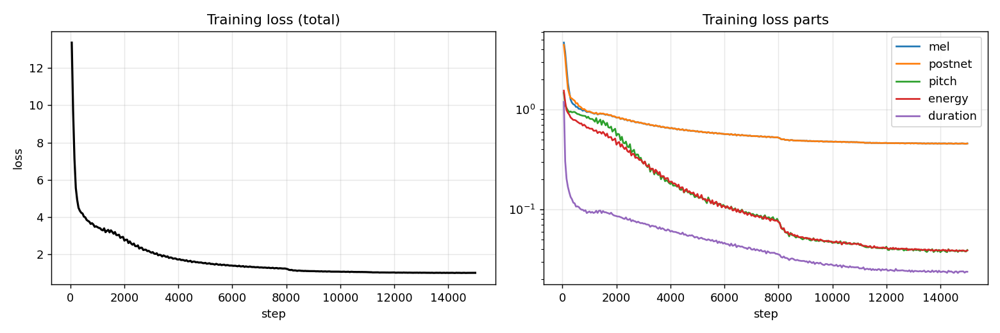

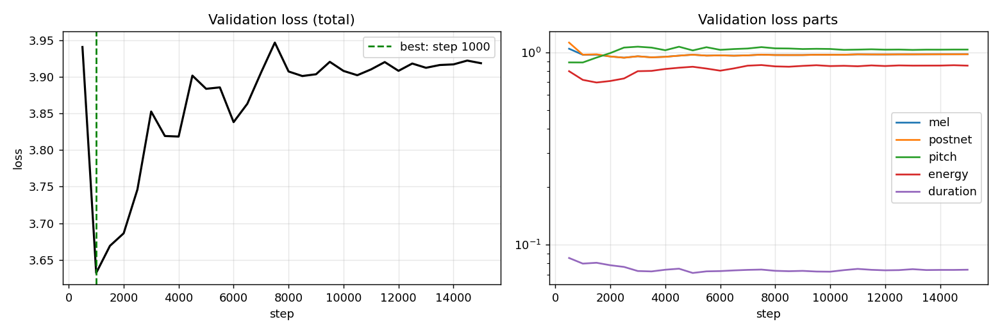

In [24]:
from IPython.display import Image, display
for p in ['training_loss.png', 'validation_loss.png']:
    display(Image('/content/project/Results/Telugu/' + p))

## 16. Additional experiment
Telugu number / time normalisation off for T4 (the sentence containing 2026, 12వ and 10:45), to show what the rule-based
normaliser contributes.

In [25]:
sh('python Telugu/inference.py --checkpoint ' + SEL + ' --no_normalize --out_dir /content/project/Results/Telugu/extra/no_normalisation')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/snapshots/step_6000_fp16.pth
Removing weight norm...
main speaker: 1 (id 1); 2 speakers in model
T1: 66 phones, 4.55 s
T2a: 31 phones, 2.21 s
T2b: 37 phones, 2.18 s
T3: 31 phones, 1.96 s
T4: 83 phones, 4.98 s
done. audio -> /content/project/Results/Telugu/extra/no_normalisation/test_generated_audios | plots -> /content/project/Results/Telugu/extra/no_normalisation/variance_adaptor_plots


'/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.\n  WeightNorm.apply(module, name, dim)\ncheckpoint: /content/work/ckpt/snapshots/step_6000_fp16.pth\nRemoving weight norm...\nmain speaker: 1 (id 1); 2 speakers in model\nT1: 66 phones, 4.55 s\nT2a: 31 phones, 2.21 s\nT2b: 37 phones, 2.18 s\nT3: 31 phones, 1.96 s\nT4: 83 phones, 4.98 s\ndone. audio -> /content/project/Results/Telugu/extra/no_normalisation/test_generated_audios | plots -> /content/project/Results/Telugu/extra/no_normalisation/variance_adaptor_plots\n'

## 17. Export
Copies the checkpoints (fp16 weights, ~70 MB each), the dataset statistics and the loss logs next to the results, and writes two archives to Drive.

In [26]:
os.makedirs('/content/project/Telugu/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_telugu/ckpt/' + f, '/content/project/Telugu/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/Telugu/')
shutil.make_archive('/content/drive/MyDrive/Telugu_results', 'zip', '/content/project', 'Results/Telugu')
shutil.make_archive('/content/drive/MyDrive/Telugu_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
print('saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)')

saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)


## 18. Real recording vs generated speech
Five held-out validation sentences (never used for training). Each is played first as the real recording, rebuilt from its stored spectrogram through the vocoder, then as the speech the model generates from the text alone. Uses the checkpoint chosen in section 14b.

In [27]:
import os, sys, torch, IPython.display as ipd
os.chdir('/content/project'); sys.path.insert(0, '/content/project')
from common.configio import load_config, setup_paths
setup_paths()
from torch.utils.data import DataLoader
cfg, configs = load_config('/content/project/Telugu/config.yaml')
pre, mod, tr = configs
from dataset import Dataset
from model import FastSpeech2
from utils.model import get_vocoder, vocoder_infer
from utils.tools import to_device
from common import synth
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']; hop = pre['preprocessing']['stft']['hop_length']
model = FastSpeech2(pre, mod).to(dev); synth.load_weights(model, SEL, dev)
ds = Dataset('val.txt', pre, tr, sort=False, drop_last=False)
loader = DataLoader(ds, batch_size=8, shuffle=False, collate_fn=ds.collate_fn)
batch = to_device(next(iter(loader))[0], dev)
ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, *_ = batch
def wav(mel, frames):
    return vocoder_infer(mel.unsqueeze(0).transpose(1, 2), voc, mod, pre, lengths=[frames * hop])[0]
for i in range(5):
    T, L = int(mel_lens[i]), int(src_lens[i])
    with torch.no_grad():
        pr = model(spk[i:i+1], texts[i:i+1, :L], src_lens[i:i+1], L)
    pm = int(pr[9][0])
    print(raw[i])
    print('REAL recording:'); ipd.display(ipd.Audio(wav(mels[i, :T], T), rate=sr))
    print('MODEL generated:'); ipd.display(ipd.Audio(wav(pr[1][0, :pm], pm), rate=sr))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Removing weight norm...
బాబూ ఇది పద్మం కాదు అసిధారా చక్రం అన్నాడు నరకవాసి.
REAL recording:


MODEL generated:


నీకు వచ్చిన లోటేమిటి అన్ని ఏర్పాట్లు అయ్యాక పెళ్ళి ఎట్లా ఆగుతుంది నన్ను వేధించకు అన్నాడు లోహితుడు.
REAL recording:


MODEL generated:


జాతకాలను నమ్మటానికి లేదు బ్రహ్మ ఎవరికి ఎంత ఆయుస్సు ఇచ్చాడో ఏ జ్యోతిష్కుడు చెప్పలేడు అన్నారు బంధువులు.
REAL recording:


MODEL generated:


జమీందారు వెళ్ళిపోయాక ఆయన భార్య చలాసేపు యోచించింది మతి సరిగాలేని తన భర్త చెప్పాడుగదా అని ఉరి పోసుకు చావటం ఆమె కెంతమాత్రం ఇష్ఠంలేదు.
REAL recording:


MODEL generated:


వంశగౌరవానికి కావాల్సింది నరబలేగదా అటువంటప్పుడు ఎవరు బలి అయితే నేం.
REAL recording:


MODEL generated:


## 19. Export of the version 2 results
Adds the checkpoint selected in section 14b to the checkpoints folder and writes the version 2 archives to Drive, named separately from the version 1 archives.

In [28]:
import shutil, os
shutil.copy(SEL, '/content/project/Telugu/checkpoints/selected_model_fp16.pth')
shutil.make_archive('/content/drive/MyDrive/Telugu_v2_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
shutil.make_archive('/content/drive/MyDrive/Telugu_v2_results', 'zip', '/content/project', 'Results/Telugu')
print(os.listdir('/content/project/Telugu/checkpoints'))
print('saved Telugu_v2_checkpoints.zip and Telugu_v2_results.zip')

['last_model_fp16.pth', 'selected_model_fp16.pth', 'best_model_fp16.pth']
saved Telugu_v2_checkpoints.zip and Telugu_v2_results.zip


In [6]:
import IPython.display as ipd
for STEP in (6000, 15000):
    CK = f'/content/drive/MyDrive/fs2_telugu/ckpt/snapshots/step_{STEP}_fp16.pth'
    out = f'/content/project/Results/Telugu/extra/try_step_{STEP}'
    sh(f'python Telugu/inference.py --checkpoint {CK} --out_dir {out}')
for STEP in (6000, 15000):
    print('===== step', STEP, '(selected by the metric)' if STEP == 6000 else '(last)')
    for w in sorted(glob.glob(f'/content/project/Results/Telugu/extra/try_step_{STEP}/test_generated_audios/*.wav')):
        print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/drive/MyDrive/fs2_telugu/ckpt/snapshots/step_6000_fp16.pth
Removing weight norm...
main speaker: 1 (id 1); 2 speakers in model
T1: 66 phones, 4.55 s
T2a: 31 phones, 2.21 s
T2b: 37 phones, 2.18 s
T3: 31 phones, 1.96 s
T4: 120 phones, 7.06 s
done. audio -> /content/project/Results/Telugu/extra/try_step_6000/test_generated_audios | plots -> /content/project/Results/Telugu/extra/try_step_6000/variance_adaptor_plots
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/drive/MyDrive/fs2_telugu/ckpt/snapshots/step_15000_fp16.pth
Removing weight norm...

T2a.wav


T2b.wav


T3.wav


T4.wav


===== step 15000 (last)
T1.wav


T2a.wav


T2b.wav


T3.wav


T4.wav


In [7]:
import os, sys, torch, IPython.display as ipd
os.chdir('/content/project'); sys.path.insert(0, '/content/project')
from common.configio import load_config, setup_paths
setup_paths()
from torch.utils.data import DataLoader
cfg, configs = load_config('/content/project/Telugu/config.yaml')
pre, mod, tr = configs
from dataset import Dataset
from model import FastSpeech2
from utils.model import get_vocoder, vocoder_infer
from utils.tools import to_device
from common import synth
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']; hop = pre['preprocessing']['stft']['hop_length']
model = FastSpeech2(pre, mod).to(dev)
synth.load_weights(model, '/content/drive/MyDrive/fs2_telugu/ckpt/snapshots/step_15000_fp16.pth', dev)
ds = Dataset('val.txt', pre, tr, sort=False, drop_last=False)
loader = DataLoader(ds, batch_size=8, shuffle=False, collate_fn=ds.collate_fn)
batch = to_device(next(iter(loader))[0], dev)
ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, *_ = batch
def wav(mel, frames):
    return vocoder_infer(mel.unsqueeze(0).transpose(1, 2), voc, mod, pre, lengths=[frames * hop])[0]
for i in range(5):
    T, L = int(mel_lens[i]), int(src_lens[i])
    with torch.no_grad():
        pr = model(spk[i:i+1], texts[i:i+1, :L], src_lens[i:i+1], L)
    pm = int(pr[9][0])
    print(raw[i])
    print('REAL recording:'); ipd.display(ipd.Audio(wav(mels[i, :T], T), rate=sr))
    print('MODEL generated (step 15000):'); ipd.display(ipd.Audio(wav(pr[1][0, :pm], pm), rate=sr))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Removing weight norm...
బాబూ ఇది పద్మం కాదు అసిధారా చక్రం అన్నాడు నరకవాసి.
REAL recording:


MODEL generated (step 15000):


నీకు వచ్చిన లోటేమిటి అన్ని ఏర్పాట్లు అయ్యాక పెళ్ళి ఎట్లా ఆగుతుంది నన్ను వేధించకు అన్నాడు లోహితుడు.
REAL recording:


MODEL generated (step 15000):


జాతకాలను నమ్మటానికి లేదు బ్రహ్మ ఎవరికి ఎంత ఆయుస్సు ఇచ్చాడో ఏ జ్యోతిష్కుడు చెప్పలేడు అన్నారు బంధువులు.
REAL recording:


MODEL generated (step 15000):


జమీందారు వెళ్ళిపోయాక ఆయన భార్య చలాసేపు యోచించింది మతి సరిగాలేని తన భర్త చెప్పాడుగదా అని ఉరి పోసుకు చావటం ఆమె కెంతమాత్రం ఇష్ఠంలేదు.
REAL recording:


MODEL generated (step 15000):


వంశగౌరవానికి కావాల్సింది నరబలేగదా అటువంటప్పుడు ఎవరు బలి అయితే నేం.
REAL recording:


MODEL generated (step 15000):


In [8]:
import os, shutil, glob, zipfile
for z in ('Telugu_v2_results.zip', 'Telugu_v2_checkpoints.zip'):
    zipfile.ZipFile('/content/drive/MyDrive/' + z).extractall('/content/project')
R = '/content/project/Results/Telugu'
keep = R + '/extra/objective_pick_step6000'
os.makedirs(keep, exist_ok=True)
for sub in ('test_generated_audios', 'variance_adaptor_plots'):
    if os.path.exists(f'{R}/{sub}'):
        shutil.rmtree(f'{keep}/{sub}', ignore_errors=True)
        shutil.move(f'{R}/{sub}', f'{keep}/{sub}')
    shutil.copytree(f'{R}/extra/try_step_15000/{sub}', f'{R}/{sub}')
shutil.copy('/content/drive/MyDrive/fs2_telugu/ckpt/snapshots/step_15000_fp16.pth', '/content/project/Telugu/checkpoints/selected_model_fp16.pth')
open(R + '/final_checkpoint.txt', 'w').write('Final Telugu checkpoint: step 15000 (chosen by listening). The spectrogram-distance metric had ranked step 6000 first; its outputs are in extra/objective_pick_step6000.\n')
shutil.make_archive('/content/drive/MyDrive/Telugu_v2_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
shutil.make_archive('/content/drive/MyDrive/Telugu_v2_results', 'zip', '/content/project', 'Results/Telugu')
print(sorted(os.listdir(R)))
print(len(glob.glob(R + '/test_generated_audios/*.wav')), 'test audios in main results')

['extra', 'final_checkpoint.txt', 'preprocess_summary.json', 'selection_stats.json', 'test_generated_audios', 'train_loss.csv', 'training_loss.png', 'val_loss.csv', 'validation_loss.png', 'variance_adaptor_plots', 'variance_adaptor_values.json']
5 test audios in main results


/extra/checkpoint_selection/checkpoint_metrics.png


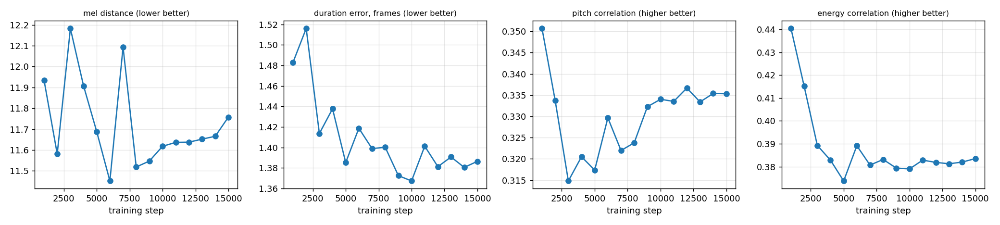

/variance_adaptor_plots/T1_mel.png


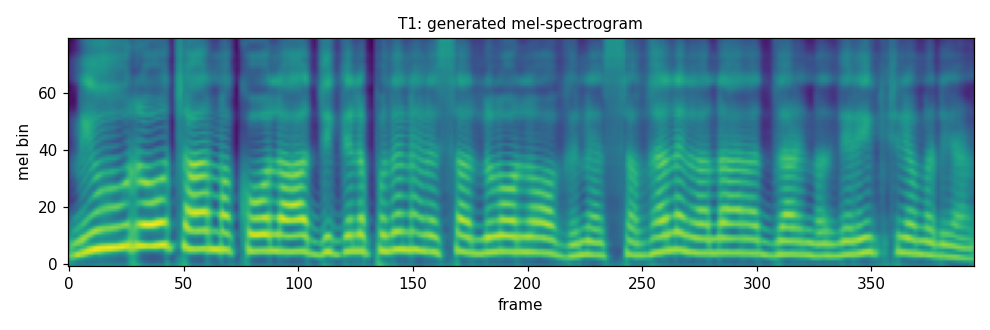

/variance_adaptor_plots/T2a_mel.png


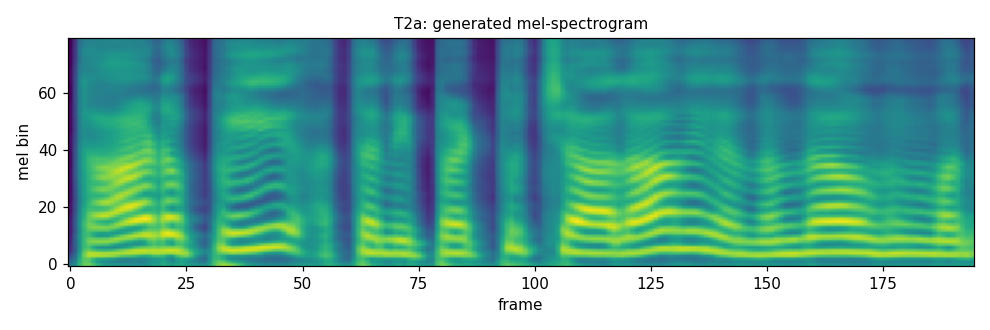

/variance_adaptor_plots/T2b_mel.png


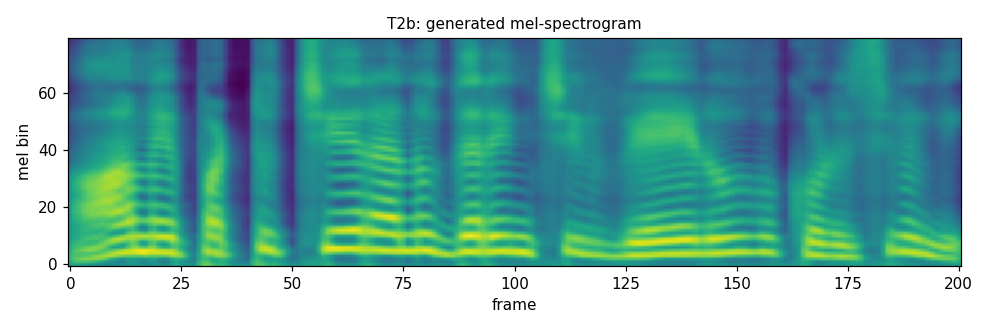

/variance_adaptor_plots/T3_mel.png


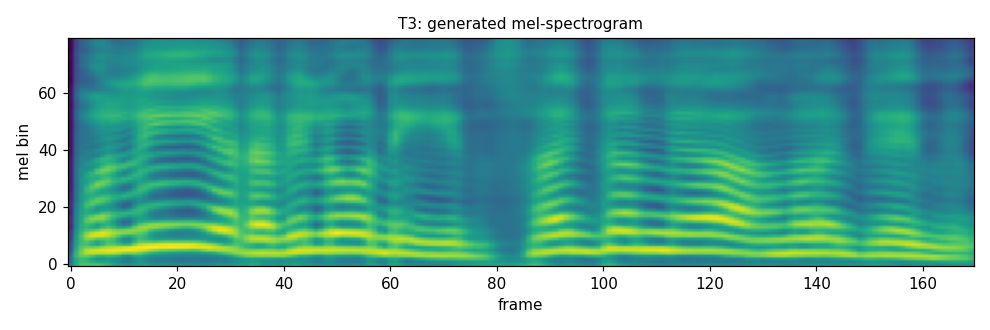

/variance_adaptor_plots/T4_mel.png


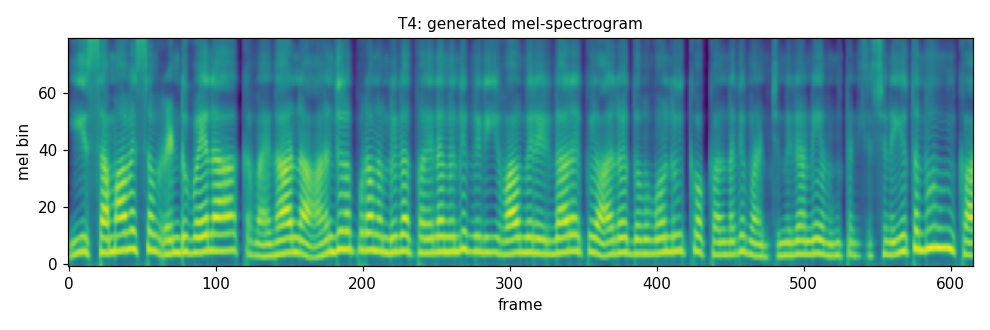

/variance_adaptor_plots/duration/T1.png


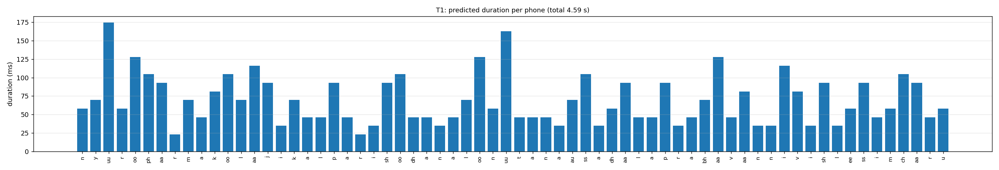

/variance_adaptor_plots/duration/T2a.png


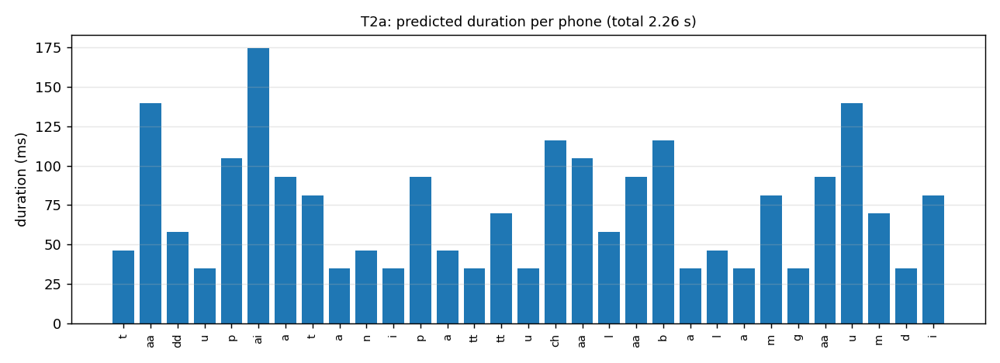

/variance_adaptor_plots/duration/T2b.png


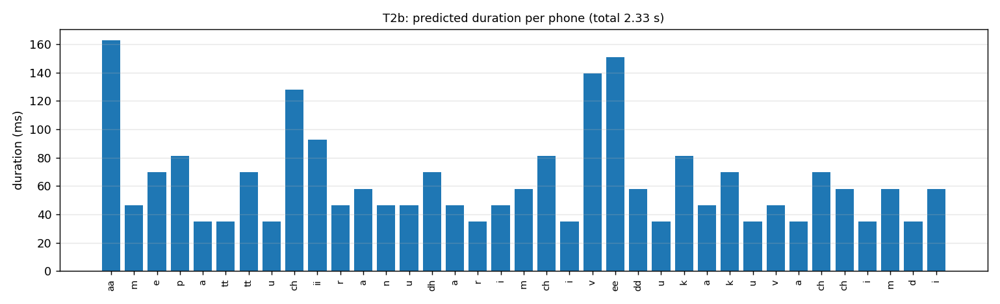

/variance_adaptor_plots/duration/T3.png


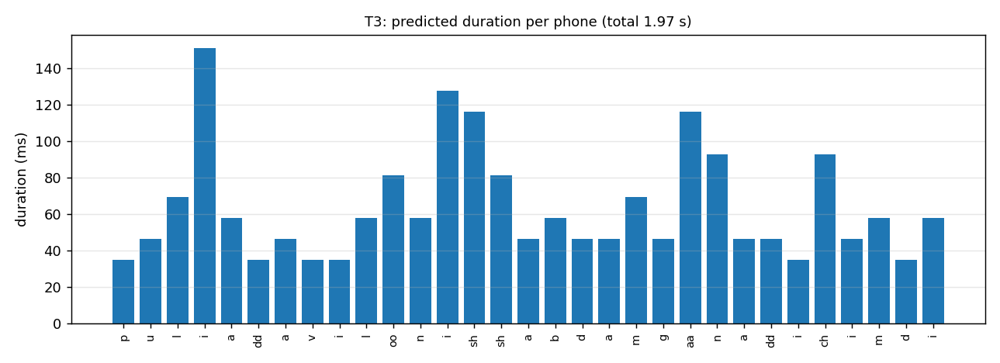

/variance_adaptor_plots/duration/T4.png


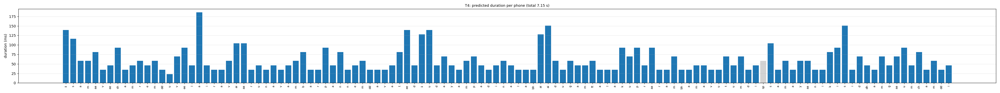

/variance_adaptor_plots/energy/T1.png


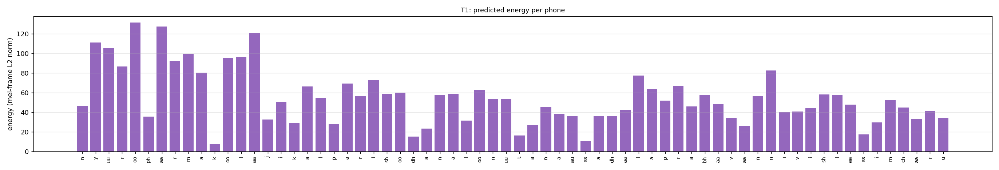

/variance_adaptor_plots/energy/T2a.png


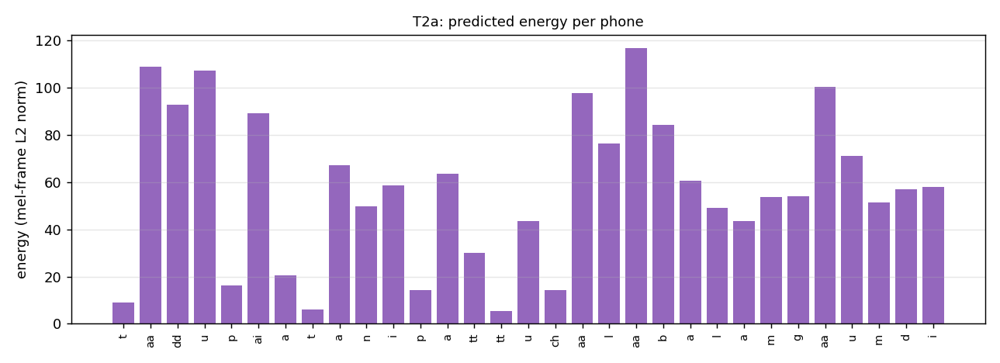

/variance_adaptor_plots/energy/T2b.png


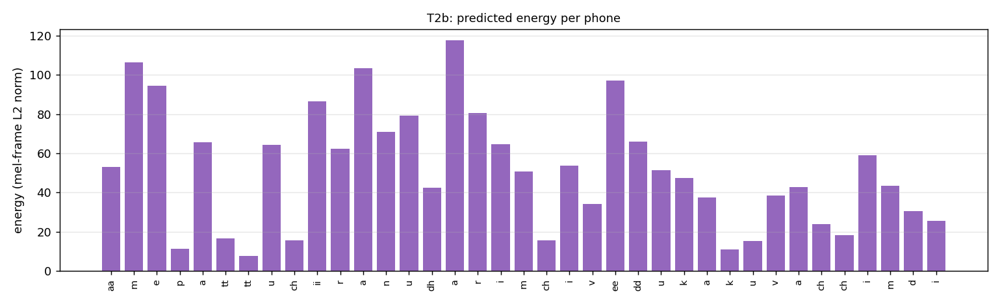

/variance_adaptor_plots/energy/T3.png


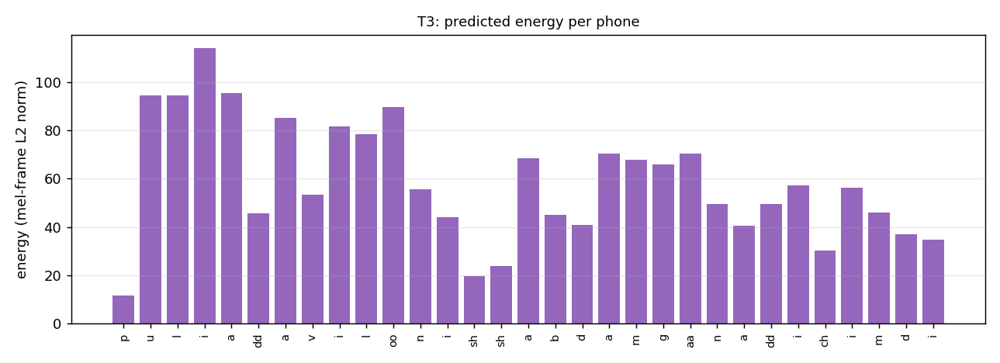

/variance_adaptor_plots/energy/T4.png


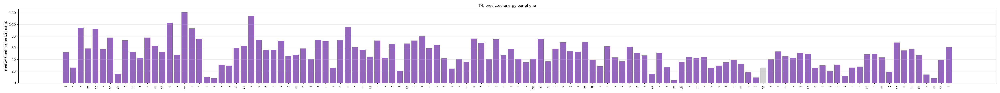

/variance_adaptor_plots/pitch/T1.png


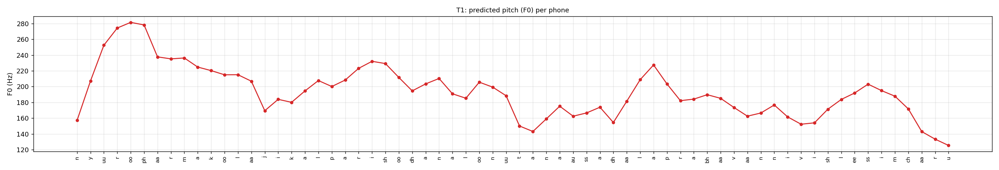

/variance_adaptor_plots/pitch/T2a.png


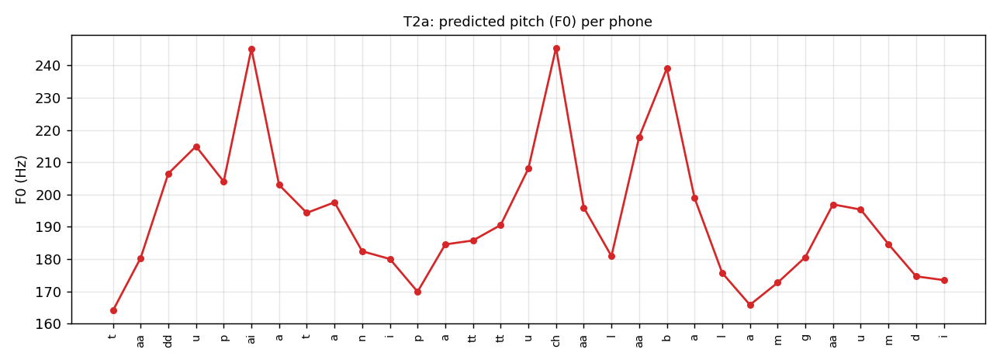

/variance_adaptor_plots/pitch/T2b.png


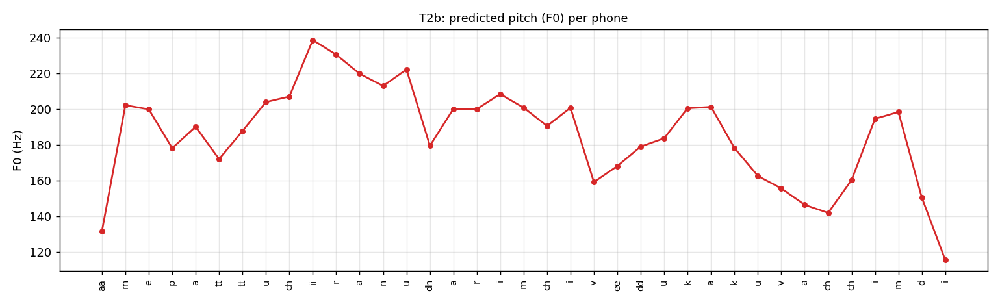

/variance_adaptor_plots/pitch/T3.png


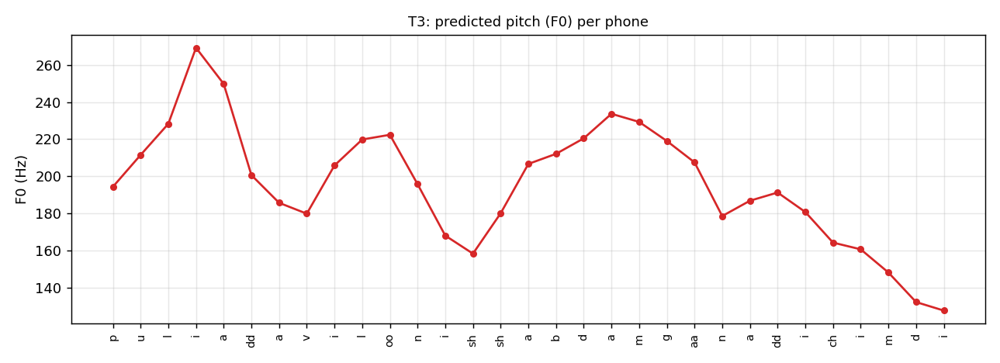

/variance_adaptor_plots/pitch/T4.png


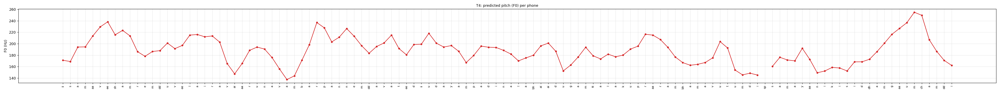

In [9]:
import os, glob
from IPython.display import Image, display
R = '/content/project/Results/Telugu'
files = [R + '/extra/checkpoint_selection/checkpoint_metrics.png'] + sorted(glob.glob(R + '/variance_adaptor_plots/**/*.png', recursive=True))
for p in files:
    if os.path.exists(p):
        print(p.replace(R, '')); display(Image(p))